In [1]:

import pandas as pd
import numpy as np

# Load the cleaned retail dataset
file_path = r"C:\Users\adria\Downloads\cleaned_output\retail_master_transactions.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

df.head()


Dataset loaded successfully!
Shape: (18000, 39)

Available columns:
['transaction_id', 'customer_id', 'product_id', 'timestamp', 'quantity', 'unit_price', 'discount_pct', 'status', 'channel', 'payment_method', 'quality_invalid_quantity', 'quality_invalid_unit_price', 'quality_invalid_discount', 'quality_invalid_timestamp', 'region', 'customer_segment', 'signup_date', 'preferred_channel', 'category', 'unit_cost', 'list_price', 'supplier_lead_days', 'gross_line_value', 'estimated_discount_value', 'estimated_discounted_line_value', 'estimated_line_cost', 'estimated_line_margin_before_returns', 'transaction_date', 'inventory_date', 'stock_on_hand', 'reorder_threshold', 'stockout_flag', 'supplier_delay_days', 'inventory_source_rows', 'inventory_record_ids', 'inventory_duplicate_date_group', 'inventory_below_reorder_threshold', 'inventory_snapshot_age_days', 'inventory_snapshot_stale_over_30_days']


,transaction_id,customer_id,product_id,timestamp,quantity,unit_price,discount_pct,status,channel,payment_method,...,stock_on_hand,reorder_threshold,stockout_flag,supplier_delay_days,inventory_source_rows,inventory_record_ids,inventory_duplicate_date_group,inventory_below_reorder_threshold,inventory_snapshot_age_days,inventory_snapshot_stale_over_30_days
0,TX015710,CU00849,PR0198,2025-01-01 00:11:00,1,320.96,0.10,Completed,Web,UPI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,TX009958,CU02489,PR0050,2025-01-01 00:45:00,3,161.35,0.25,Cancelled,App,NetBanking,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,TX010201,CU02234,PR0247,2025-01-01 01:36:00,4,355.48,0.00,Cancelled,App,Cash,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,TX003234,CU02435,PR0230,2025-01-01 01:55:00,3,240.79,0.15,Completed,Web,Card,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,TX004197,CU00570,PR0179,2025-01-01 02:04:00,5,350.06,0.05,Completed,Web,Card,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


In [3]:

required_columns = [
    "timestamp",
    "status",
    "product_id",
    "category",
    "quantity"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing required columns:", missing_columns)
else:
    print("All required columns are available!")

    print("\nTransaction statuses:")
    print(df["status"].value_counts(dropna=False))

    print("\nDate range:")
    print(df["timestamp"].min(), "to", df["timestamp"].max())

    print("\nQuantity data type:")
    print(df["quantity"].dtype)


All required columns are available!

Transaction statuses:
status
Completed    13962
Cancelled     1689
Returned      1431
Pending        918
Name: count, dtype: int64

Date range:
2025-01-01 00:11:00 to 2025-12-31 23:53:00

Quantity data type:
int64


In [4]:

# Step 4: Prepare the data for demand prediction

# Make sure the required columns have the correct data types
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")

# Keep completed transactions with valid dates and quantities
completed_df = df[
    df["status"].astype("string").str.strip().str.title().eq("Completed")
    & df["timestamp"].notna()
    & df["quantity"].notna()
].copy()

# Extract the calendar date
completed_df["date"] = completed_df["timestamp"].dt.normalize()

# Summarize total units sold per product per day
daily_demand = (
    completed_df
    .groupby(["date", "product_id", "category"], as_index=False)
    .agg(units_sold=("quantity", "sum"))
)

print("Completed transaction lines:", len(completed_df))
print("Daily product records:", len(daily_demand))
print("\nSample daily demand:")
display(daily_demand.head(10))

print("\nDate range:")
print(daily_demand["date"].min(), "to", daily_demand["date"].max())

print("\nUnique products:", daily_demand["product_id"].nunique())


Completed transaction lines: 13962
Daily product records: 12916

Sample daily demand:


,date,product_id,category,units_sold
0,2025-01-01,PR0001,Sports,2
1,2025-01-01,PR0004,Sports,4
2,2025-01-01,PR0008,Beauty,5
3,2025-01-01,PR0009,Electronics,5
4,2025-01-01,PR0010,Beauty,2
5,2025-01-01,PR0013,Home,4
6,2025-01-01,PR0015,Grocery,3
7,2025-01-01,PR0028,Grocery,5
8,2025-01-01,PR0029,Electronics,2
9,2025-01-01,PR0031,Grocery,2



Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

Unique products: 250


In [5]:

# Step 5: Build a complete product-by-date dataset

# Use the dates and products available in the cleaned dataset
all_dates = pd.date_range(
    start=daily_demand["date"].min(),
    end=daily_demand["date"].max(),
    freq="D"
)

product_info = (
    completed_df[["product_id", "category"]]
    .dropna(subset=["product_id"])
    .drop_duplicates(subset=["product_id"])
)

# Create every date-product combination
date_product_grid = pd.MultiIndex.from_product(
    [all_dates, product_info["product_id"].unique()],
    names=["date", "product_id"]
).to_frame(index=False)

# Attach product categories
date_product_grid = date_product_grid.merge(
    product_info,
    on="product_id",
    how="left"
)

# Add observed sales and fill missing days with zero recorded sales
daily_demand_full = date_product_grid.merge(
    daily_demand[["date", "product_id", "units_sold"]],
    on=["date", "product_id"],
    how="left"
)

daily_demand_full["units_sold"] = (
    daily_demand_full["units_sold"].fillna(0)
)

daily_demand_full = daily_demand_full.sort_values(
    ["product_id", "date"]
).reset_index(drop=True)

print("Prepared dataset shape:", daily_demand_full.shape)
print("Number of dates:", daily_demand_full["date"].nunique())
print("Number of products:", daily_demand_full["product_id"].nunique())
print("\nSample:")
display(daily_demand_full.head(10))


Prepared dataset shape: (91250, 4)
Number of dates: 365
Number of products: 250

Sample:


,date,product_id,category,units_sold
0,2025-01-01,PR0001,Sports,2.0
1,2025-01-02,PR0001,Sports,2.0
2,2025-01-03,PR0001,Sports,0.0
3,2025-01-04,PR0001,Sports,0.0
4,2025-01-05,PR0001,Sports,0.0
5,2025-01-06,PR0001,Sports,0.0
6,2025-01-07,PR0001,Sports,0.0
7,2025-01-08,PR0001,Sports,0.0
8,2025-01-09,PR0001,Sports,0.0
9,2025-01-10,PR0001,Sports,0.0


In [6]:

# Step 6: Feature engineering

import pandas as pd
import numpy as np

ml_df = daily_demand_full.copy()
ml_df["date"] = pd.to_datetime(ml_df["date"])

ml_df = ml_df.sort_values(
    ["product_id", "date"]
).reset_index(drop=True)

# Calendar features
ml_df["month"] = ml_df["date"].dt.month
ml_df["day_of_week"] = ml_df["date"].dt.dayofweek
ml_df["day_of_year"] = ml_df["date"].dt.dayofyear
ml_df["is_weekend"] = (
    ml_df["day_of_week"] >= 5
).astype(int)

# Historical demand features, calculated only from earlier days
product_groups = ml_df.groupby("product_id")["units_sold"]

ml_df["lag_1"] = product_groups.shift(1)
ml_df["lag_7"] = product_groups.shift(7)

ml_df["rolling_mean_7"] = (
    ml_df.groupby("product_id")["units_sold"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7, min_periods=1
        ).mean()
    )
)

# Early dates have no earlier sales history
ml_df[["lag_1", "lag_7", "rolling_mean_7"]] = (
    ml_df[["lag_1", "lag_7", "rolling_mean_7"]]
    .fillna(0)
)

print("Feature dataset shape:", ml_df.shape)
display(ml_df.head(10))


Feature dataset shape: (91250, 11)


,date,product_id,category,units_sold,month,day_of_week,day_of_year,is_weekend,lag_1,lag_7,rolling_mean_7
0,2025-01-01,PR0001,Sports,2.0,1,2,1,0,0.0,0.0,0.000000
1,2025-01-02,PR0001,Sports,2.0,1,3,2,0,2.0,0.0,2.000000
2,2025-01-03,PR0001,Sports,0.0,1,4,3,0,2.0,0.0,2.000000
3,2025-01-04,PR0001,Sports,0.0,1,5,4,1,0.0,0.0,1.333333
4,2025-01-05,PR0001,Sports,0.0,1,6,5,1,0.0,0.0,1.000000
5,2025-01-06,PR0001,Sports,0.0,1,0,6,0,0.0,0.0,0.800000
6,2025-01-07,PR0001,Sports,0.0,1,1,7,0,0.0,0.0,0.666667
7,2025-01-08,PR0001,Sports,0.0,1,2,8,0,0.0,2.0,0.571429
8,2025-01-09,PR0001,Sports,0.0,1,3,9,0,0.0,2.0,0.285714
9,2025-01-10,PR0001,Sports,0.0,1,4,10,0,0.0,0.0,0.000000


In [8]:

# Step 7: Train and evaluate the model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Model inputs and target
feature_columns = [
    "product_id",
    "category",
    "month",
    "day_of_week",
    "day_of_year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "rolling_mean_7"
]

categorical_features = ["product_id", "category"]

numeric_features = [
    "month",
    "day_of_week",
    "day_of_year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "rolling_mean_7"
]

# Chronological split: final 20% of dates reserved for testing
unique_dates = np.sort(ml_df["date"].unique())
cutoff_index = int(len(unique_dates) * 0.80)
cutoff_date = pd.Timestamp(unique_dates[cutoff_index])

train_df = ml_df[ml_df["date"] < cutoff_date].copy()
test_df = ml_df[ml_df["date"] >= cutoff_date].copy()

X_train = train_df[feature_columns]
y_train = train_df["units_sold"]

X_test = test_df[feature_columns]
y_test = test_df["units_sold"]

# Encode categorical features and keep numeric features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=150,
                max_depth=18,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Training started...")
model.fit(X_train, y_train)

# Predict daily demand for the test period
predictions = model.predict(X_test)

# Demand cannot be negative, so clip negative predictions to zero
predictions = np.maximum(predictions, 0)

# Simple baseline: use the previous 7-day average
baseline_predictions = test_df["rolling_mean_7"].to_numpy()

# Calculate evaluation metrics
model_mae = mean_absolute_error(y_test, predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, predictions))

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("\nMODEL TRAINING COMPLETE")
print("-----------------------")
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training ends before:", cutoff_date.date())
print("Testing starts:", cutoff_date.date())

print("\nRandom Forest performance")
print(f"MAE:  {model_mae:.3f} units")
print(f"RMSE: {model_rmse:.3f} units")

print("\n7-day baseline performance")
print(f"MAE:  {baseline_mae:.3f} units")
print(f"RMSE: {baseline_rmse:.3f} units")


Training started...

MODEL TRAINING COMPLETE
-----------------------
Training rows: 73000
Testing rows: 18250
Training ends before: 2025-10-20
Testing starts: 2025-10-20

Random Forest performance
MAE:  0.850 units
RMSE: 1.288 units

7-day baseline performance
MAE:  0.770 units
RMSE: 1.364 units


In [9]:

# Step 8: Build a predictions table

results = test_df[
    ["date", "product_id", "category", "units_sold"]
].copy()

results = results.rename(
    columns={"units_sold": "actual_units_sold"}
)

results["predicted_units_sold"] = predictions
results["baseline_predicted_units"] = baseline_predictions

results["absolute_error"] = (
    results["actual_units_sold"]
    - results["predicted_units_sold"]
).abs()

print("Sample predictions:")
display(results.head(15))

# Overall actual and predicted totals for the test period
print("\nTotal actual units:", round(results["actual_units_sold"].sum(), 2))
print("Total predicted units:", round(results["predicted_units_sold"].sum(), 2))


Sample predictions:


,date,product_id,category,actual_units_sold,predicted_units_sold,baseline_predicted_units,absolute_error
292,2025-10-20,PR0001,Sports,0.0,0.518440,0.000000,0.518440
293,2025-10-21,PR0001,Sports,0.0,0.505106,0.000000,0.505106
294,2025-10-22,PR0001,Sports,0.0,0.504710,0.000000,0.504710
295,2025-10-23,PR0001,Sports,0.0,0.507438,0.000000,0.507438
296,2025-10-24,PR0001,Sports,1.0,0.523386,0.000000,0.476614
297,2025-10-25,PR0001,Sports,1.0,0.550150,0.142857,0.449850
298,2025-10-26,PR0001,Sports,0.0,0.505329,0.285714,0.505329
299,2025-10-27,PR0001,Sports,0.0,0.476775,0.285714,0.476775
300,2025-10-28,PR0001,Sports,0.0,0.464284,0.285714,0.464284
301,2025-10-29,PR0001,Sports,0.0,0.464284,0.285714,0.464284



Total actual units: 8115.0
Total predicted units: 10215.72


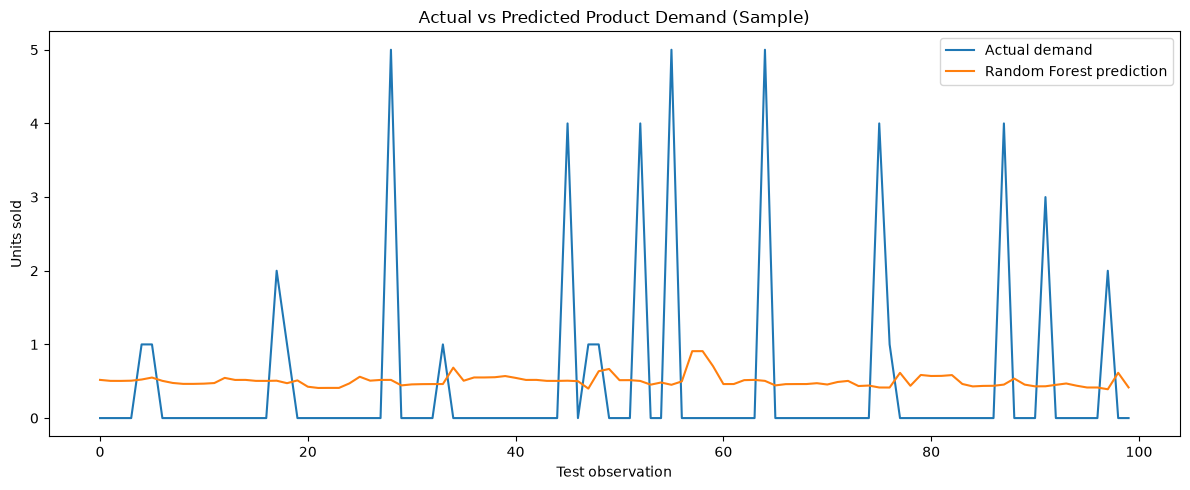

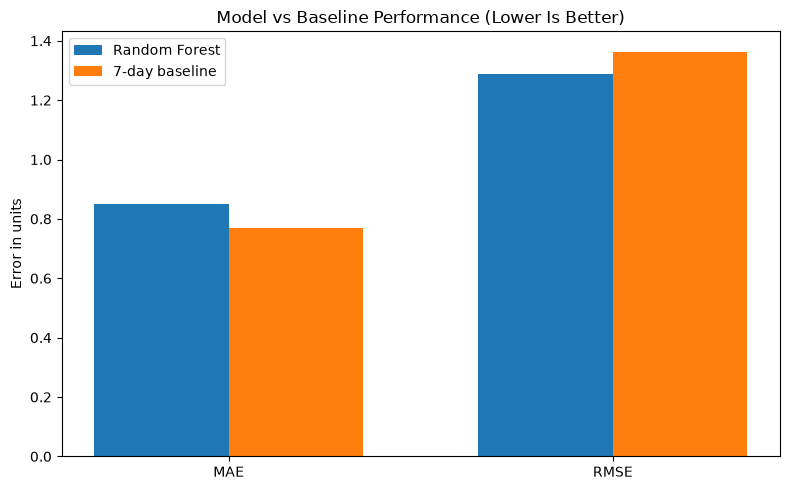

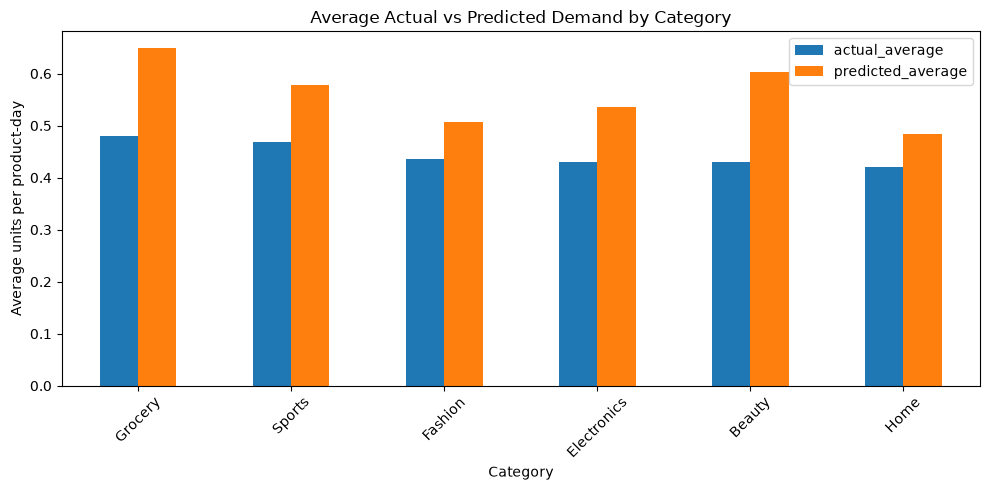

In [10]:

# Step 9: Evaluation charts

import matplotlib.pyplot as plt

# Chart 1: Actual vs predicted demand for a sample of test rows
sample_results = results.head(100).reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(
    sample_results.index,
    sample_results["actual_units_sold"],
    label="Actual demand"
)
plt.plot(
    sample_results.index,
    sample_results["predicted_units_sold"],
    label="Random Forest prediction"
)
plt.title("Actual vs Predicted Product Demand (Sample)")
plt.xlabel("Test observation")
plt.ylabel("Units sold")
plt.legend()
plt.tight_layout()
plt.show()

# Chart 2: Compare error metrics
metric_names = ["MAE", "RMSE"]

model_scores = [model_mae, model_rmse]
baseline_scores = [baseline_mae, baseline_rmse]

x = np.arange(len(metric_names))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, model_scores, width, label="Random Forest")
plt.bar(x + width / 2, baseline_scores, width, label="7-day baseline")
plt.xticks(x, metric_names)
plt.ylabel("Error in units")
plt.title("Model vs Baseline Performance (Lower Is Better)")
plt.legend()
plt.tight_layout()
plt.show()

# Chart 3: Average actual and predicted demand by category
category_results = (
    results.groupby("category", as_index=False)
    .agg(
        actual_average=("actual_units_sold", "mean"),
        predicted_average=("predicted_units_sold", "mean")
    )
    .sort_values("actual_average", ascending=False)
)

category_results.plot(
    x="category",
    y=["actual_average", "predicted_average"],
    kind="bar",
    figsize=(10, 5)
)
plt.title("Average Actual vs Predicted Demand by Category")
plt.xlabel("Category")
plt.ylabel("Average units per product-day")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Top 15 features used by the model:


,feature,importance
258,numeric__day_of_year,0.447768
262,numeric__rolling_mean_7,0.157885
257,numeric__day_of_week,0.131624
260,numeric__lag_1,0.048346
256,numeric__month,0.044869
261,numeric__lag_7,0.044769
259,numeric__is_weekend,0.015430
21,categorical__product_id_PR0022,0.002304
118,categorical__product_id_PR0119,0.002178
217,categorical__product_id_PR0218,0.001767


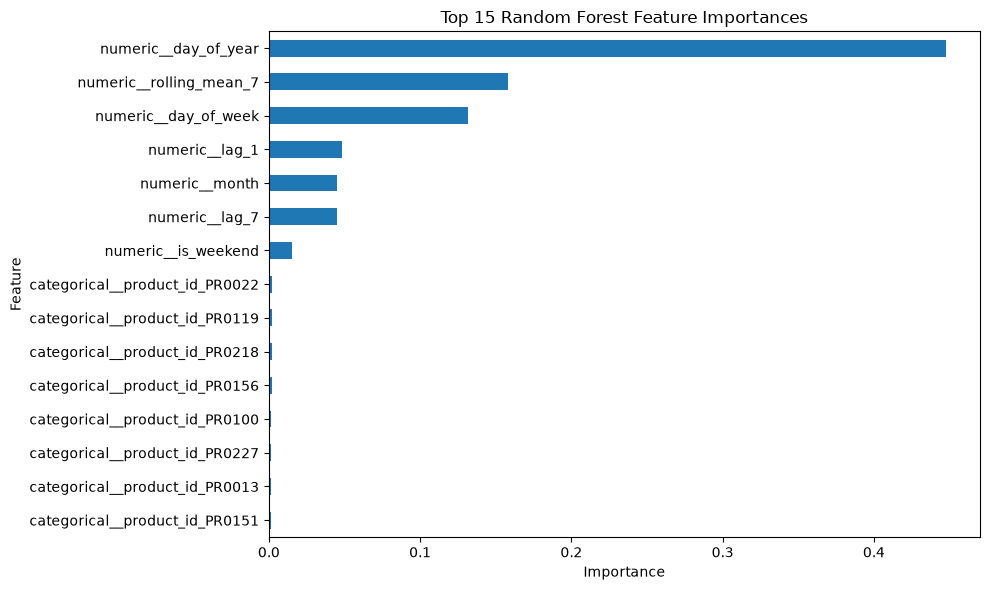

In [11]:

# Step 10: Feature importance

preprocessor_fitted = model.named_steps["preprocessor"]
rf_model = model.named_steps["regressor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 15 features used by the model:")
display(importance_df.head(15))

importance_df.head(15).sort_values("importance").plot(
    x="feature",
    y="importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [12]:

# Step 11: Save the trained model and project outputs

import os
import joblib

output_dir = "ml_model_outputs"
os.makedirs(output_dir, exist_ok=True)

# Save trained model
joblib.dump(
    model,
    os.path.join(output_dir, "retail_demand_random_forest.joblib")
)

# Save predictions
results.to_csv(
    os.path.join(output_dir, "demand_predictions.csv"),
    index=False
)

# Save feature importance
importance_df.to_csv(
    os.path.join(output_dir, "feature_importance.csv"),
    index=False
)

# Save evaluation metrics
evaluation_df = pd.DataFrame({
    "model": ["Random Forest", "7-day baseline"],
    "MAE": [model_mae, baseline_mae],
    "RMSE": [model_rmse, baseline_rmse]
})

evaluation_df.to_csv(
    os.path.join(output_dir, "model_evaluation.csv"),
    index=False
)

print("Files saved in:", os.path.abspath(output_dir))
print("\nSaved files:")
for filename in os.listdir(output_dir):
    print("-", filename)

display(evaluation_df.round(3))


Files saved in: C:\Users\adria\ml_model_outputs

Saved files:
- demand_predictions.csv
- feature_importance.csv
- model_evaluation.csv
- retail_demand_random_forest.joblib


,model,MAE,RMSE
0,Random Forest,0.85,1.288
1,7-day baseline,0.77,1.364


In [13]:

# Step 12: Generate a project summary

if model_mae < baseline_mae and model_rmse < baseline_rmse:
    comparison = (
        "Random Forest outperformed the 7-day baseline "
        "on both MAE and RMSE."
    )
elif model_mae > baseline_mae and model_rmse > baseline_rmse:
    comparison = (
        "The 7-day baseline outperformed Random Forest "
        "on both MAE and RMSE."
    )
else:
    comparison = (
        "The results are mixed: Random Forest performed better "
        "on one metric but not the other."
    )

summary = f"""
RETAIL PRODUCT DEMAND PREDICTION - ML SUMMARY

Model: Random Forest Regression
Target: Daily units sold per product
Training rows: {len(train_df):,}
Testing rows: {len(test_df):,}
Test period starts: {cutoff_date.date()}

Random Forest MAE: {model_mae:.3f} units
Random Forest RMSE: {model_rmse:.3f} units

7-day baseline MAE: {baseline_mae:.3f} units
7-day baseline RMSE: {baseline_rmse:.3f} units

Comparison:
{comparison}

Limitations:
- Historical data covers 2025 only.
- Days without recorded completed sales were treated as zero sales.
- This evaluation simulates one-day-ahead predictions using
  previously observed demand.
- Results may not generalize to future periods or changing
  business conditions.
"""

print(summary)

with open(
    os.path.join(output_dir, "ml_project_summary.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(summary)

print("Summary saved.")



RETAIL PRODUCT DEMAND PREDICTION - ML SUMMARY

Model: Random Forest Regression
Target: Daily units sold per product
Training rows: 73,000
Testing rows: 18,250
Test period starts: 2025-10-20

Random Forest MAE: 0.850 units
Random Forest RMSE: 1.288 units

7-day baseline MAE: 0.770 units
7-day baseline RMSE: 1.364 units

Comparison:
The results are mixed: Random Forest performed better on one metric but not the other.

Limitations:
- Historical data covers 2025 only.
- Days without recorded completed sales were treated as zero sales.
- This evaluation simulates one-day-ahead predictions using
  previously observed demand.
- Results may not generalize to future periods or changing
  business conditions.

Summary saved.


In [14]:

import os

print("Current notebook working folder:")
print(os.getcwd())

print("\nDoes the ML output folder exist here?")
print(os.path.exists("ml_model_outputs"))

if os.path.exists("ml_model_outputs"):
    print("\nFiles found:")
    print(os.listdir("ml_model_outputs"))


Current notebook working folder:
C:\Users\adria

Does the ML output folder exist here?
True

Files found:
['demand_predictions.csv', 'feature_importance.csv', 'ml_project_summary.txt', 'model_evaluation.csv', 'retail_demand_random_forest.joblib']
